# Static Sign-Language Alphabet Recognition
**Ramdeobaba University | Deep Learning Lab | 2026–27**

This notebook implements the lightweight-CNN option in the submitted proposal.
It uses **Akash Nagaraj's ASL Alphabet dataset**, not a replacement dataset.
Source: https://www.kaggle.com/datasets/grassknoted/asl-alphabet

**Scope:** the 24 static letters (A–Z except J and Z), plus `nothing`.
J and Z require motion; `space` and `del` are outside this selected static-letter scope.
This is a fingerspelling-classification prototype, not sentence translation or ISL recognition.

**Complete workflow:** inspect data → split → resize/augment → train a small CNN
→ evaluate → export → MediaPipe webcam hand crop → temporal voting → local-volunteer testing.

**Before Run All:** attach `grassknoted/asl-alphabet`, finish Kaggle phone verification,
and select Settings → Accelerator → GPU T4 x2. The code checks for a GPU and stops
instead of silently starting CPU training. All metrics below are produced by execution;
this source notebook contains no claimed results.


## 1. Configuration and cloud GPU check
The initial model uses one GPU to avoid synchronization overhead for a small CNN.
`USE_TWO_GPUS=True` supports a later controlled speed comparison. Keep data splits
and other settings fixed when comparing configurations. No pretrained weights are used.


In [4]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import sys, json, time, random, hashlib, re, platform, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 43
IMAGE_SIZE = 96
BATCH_SIZE = 128
MAX_EPOCHS = 30
USE_TWO_GPUS = False
BLOCK_SIZE = 100
CLASSES = [c for c in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ' if c not in 'JZ'] + ['nothing']
OUT = Path('/kaggle/working/asl_results')
OUT.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('Python:', sys.version.split()[0])
print('Visible GPUs:', gpus)
if not gpus:
    raise RuntimeError('GPU required: complete phone verification, select GPU T4 x2, then Run All again.')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
strategy = (tf.distribute.MirroredStrategy() if USE_TWO_GPUS
            else tf.distribute.OneDeviceStrategy('/GPU:0'))
print('Replicas used:', strategy.num_replicas_in_sync)
config = dict(seed=SEED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
              max_epochs=MAX_EPOCHS, classes=CLASSES, block_size=BLOCK_SIZE,
              two_gpus=USE_TWO_GPUS, dataset='grassknoted/asl-alphabet',
              tensorflow=tf.__version__, python=sys.version, platform=platform.platform())
(OUT/'config.json').write_text(json.dumps(config, indent=2))


TensorFlow: 2.20.0
Python: 3.13.15
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Replicas used: 1


556

## 2. Locate and inspect the exact dataset
Keep the original Kaggle dataset attached for attribution. For faster reading, download
the same public archive to the session's local disk and check its SHA-256 before use.
This avoids opening thousands of small images through the slower mounted input path.
Turn on Internet in Kaggle Settings. The supplied tiny test folder is not used for evaluation.


Downloaded 134 MB
Downloaded 268 MB
Downloaded 403 MB
Downloaded 537 MB
Downloaded 671 MB
Downloaded 805 MB
Downloaded 940 MB
Downloaded 1074 MB
Download seconds: 5.7
Training images: /kaggle/temp/asl_data/asl_alphabet_train/asl_alphabet_train


,images
class_name,
A,3000
B,3000
C,3000
D,3000
E,3000
F,3000
G,3000
H,3000
I,3000


Selected images: 75000 | Output classes: 25


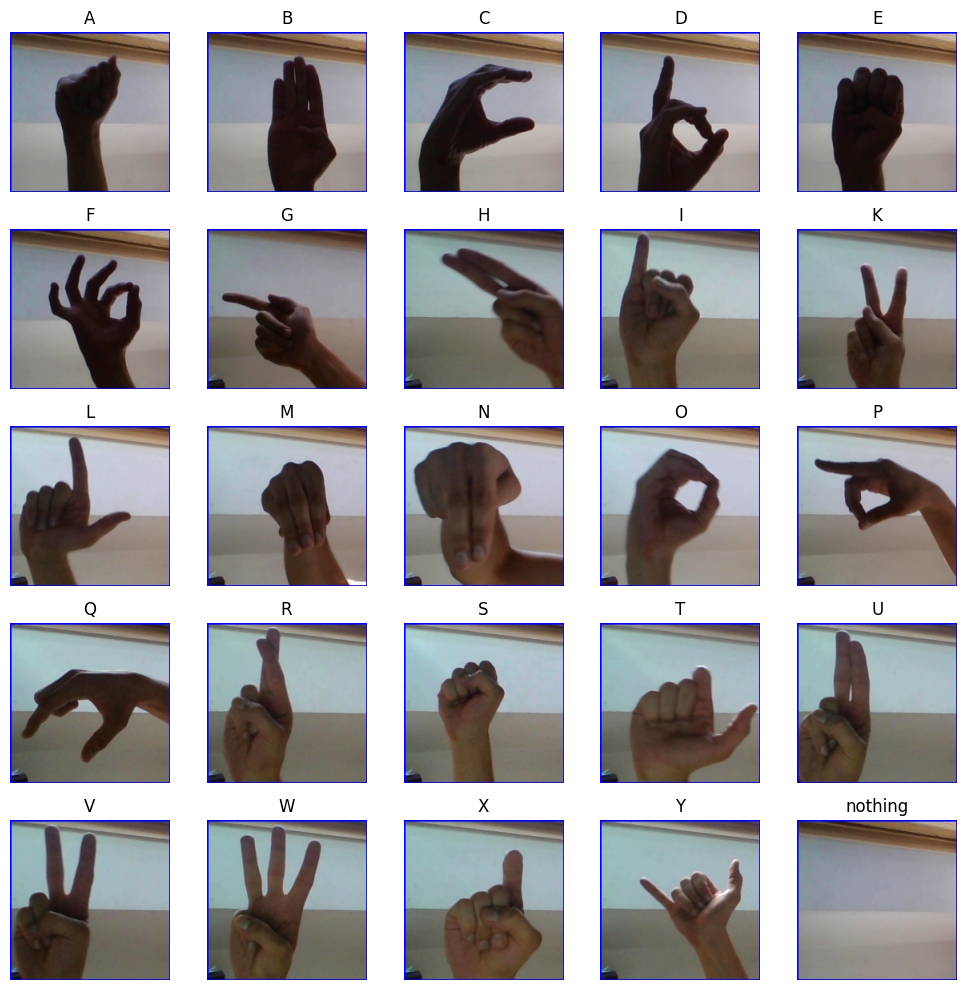

In [5]:
import urllib.request
import zipfile

archive_path = Path('/kaggle/temp/asl-alphabet.zip')
archive_path.parent.mkdir(parents=True, exist_ok=True)
expected_sha = '7c572f14fbaff94f98835cfe71c7582dd379a5176e7c4f83dbf3a30e4b3f68c4'
if not archive_path.exists():
    url = 'https://www.kaggle.com/api/v1/datasets/download/grassknoted/asl-alphabet'
    partial = archive_path.with_suffix('.part')
    started = time.perf_counter()
    with urllib.request.urlopen(url, timeout=120) as response, partial.open('wb') as f:
        downloaded = 0
        while True:
            chunk = response.read(8*1024*1024)
            if not chunk: break
            f.write(chunk)
            downloaded += len(chunk)
            if downloaded//(128*1024*1024) != (downloaded-len(chunk))//(128*1024*1024):
                print(f'Downloaded {downloaded/1e6:.0f} MB', flush=True)
    partial.replace(archive_path)
    print('Download seconds:', round(time.perf_counter()-started, 1))
digest = hashlib.sha256()
with archive_path.open('rb') as f:
    for chunk in iter(lambda: f.read(8*1024*1024), b''):
        digest.update(chunk)
if digest.hexdigest() != expected_sha:
    raise ValueError('Dataset archive checksum changed. Inspect its version before continuing.')
local_dir = Path('/kaggle/temp/asl_data')
ready = local_dir/'extraction_complete.txt'
if not ready.exists():
    with zipfile.ZipFile(archive_path) as z:
        for info in z.infolist():
            names = info.filename.split('/')
            if (len(names) == 4 and names[:2] == ['asl_alphabet_train','asl_alphabet_train']
                    and names[2] in CLASSES and names[3].endswith('.jpg') and '..' not in names):
                z.extract(info, local_dir)
    ready.write_text(expected_sha)
DATA_ROOT = local_dir/'asl_alphabet_train'/'asl_alphabet_train'
config['dataset_archive_sha256'] = expected_sha
(OUT/'config.json').write_text(json.dumps(config, indent=2))
print('Training images:', DATA_ROOT)
rows = []
for label, name in enumerate(CLASSES):
    paths = sorted(p for p in (DATA_ROOT/name).iterdir()
                   if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if len(paths) < 100:
        raise ValueError(f'Unexpected or missing data for {name}: {len(paths)} images')
    for p in paths:
        rows.append(dict(path=str(p), relative_path=str(p.relative_to(DATA_ROOT)),
                         class_name=name, label=label))
df = pd.DataFrame(rows)
display(df.groupby('class_name', sort=False).size().rename('images').to_frame())
print('Selected images:', len(df), '| Output classes:', len(CLASSES))
fig, axes = plt.subplots(5, 5, figsize=(10, 10))
for ax, name in zip(axes.flat, CLASSES):
    p = df.loc[df.class_name.eq(name), 'path'].iloc[0]
    with Image.open(p) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'class_examples.png', dpi=150); plt.show()


## 3. Audit exact duplicates and create reproducible splits
Hash files before splitting. Keep one copy of each exact duplicate; remove conflicting
labels and retain an audit CSV. To reduce leakage from consecutive captures, group
each class's numerically ordered filenames into blocks of 100 before assigning blocks
to train/validation/test (approximately 70/15/15, depending on available blocks).

**Limitation:** filename blocks are a proxy, not verified recording sessions or subjects.
The dataset does not provide reliable signer identities here, so this is not a
subject-independent split. Similar poses/backgrounds can remain across blocks.
The separate volunteer evaluation is needed for claims about new people.


In [6]:
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

audit_start = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    df['sha256'] = list(pool.map(sha256_file, df.path))
conflicts = df.groupby('sha256').class_name.nunique()
bad_hashes = set(conflicts[conflicts > 1].index)
audit = df[df.duplicated('sha256', keep=False)].copy()
audit['conflicting_labels'] = audit.sha256.isin(bad_hashes)
audit.to_csv(OUT/'duplicate_audit.csv', index=False)
original_count = len(df)
df = df[~df.sha256.isin(bad_hashes)].drop_duplicates('sha256').copy()

def numeric_index(path):
    matches = re.findall(r'\d+', Path(path).stem)
    if not matches:
        raise ValueError('Expected numbered filenames; inspect the dataset before splitting.')
    return int(matches[-1])

df['capture_block'] = df.path.map(numeric_index) // BLOCK_SIZE
df['split'] = ''
rng = np.random.default_rng(SEED)
for name in CLASSES:
    mask = df.class_name.eq(name)
    groups = np.array(sorted(df.loc[mask, 'capture_block'].unique()))
    if len(groups) < 7:
        raise ValueError(f'Not enough blocks for {name}; inspect BLOCK_SIZE.')
    rng.shuffle(groups)
    n_test = max(1, round(len(groups)*0.15))
    n_val = max(1, round(len(groups)*0.15))
    test_groups, val_groups = groups[:n_test], groups[n_test:n_test+n_val]
    df.loc[mask, 'split'] = 'train'
    df.loc[mask & df.capture_block.isin(val_groups), 'split'] = 'val'
    df.loc[mask & df.capture_block.isin(test_groups), 'split'] = 'test'

assert df.groupby(['class_name', 'capture_block']).split.nunique().max() == 1
assert df.sha256.is_unique
assert not df.split.eq('').any()
split_summary = pd.crosstab(df.class_name, df.split).reindex(CLASSES)
assert (split_summary[['train', 'val', 'test']] > 0).all().all()
display(split_summary)
df.to_csv(OUT/'split_manifest.csv', index=False)
split_summary.to_csv(OUT/'split_summary.csv')
print('Removed duplicates/conflicts:', original_count-len(df))
print('Audit seconds:', round(time.perf_counter()-audit_start, 1))


split,test,train,val
class_name,,,
A,500,2000,500
B,500,2099,401
C,500,2001,499
D,499,2001,500
E,500,2000,500
F,500,2000,500
G,500,2000,500
H,500,2100,400
I,500,2000,500


Removed duplicates/conflicts: 0
Audit seconds: 18.2


## 4. Input pipeline and augmentation
Images are decoded as RGB, padded/resized to 96 × 96, and cached as uint8 in memory.
Only training batches are shuffled and augmented. Validation/test images are untouched.
The rescaling layer lives inside the model, so inference must supply RGB in [0,255].
No horizontal flip is used, and we do not claim left/right-hand invariance.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE
def decode_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, IMAGE_SIZE, IMAGE_SIZE)
    return tf.cast(tf.clip_by_value(image, 0, 255), tf.uint8), label

parts = {s: df[df.split.eq(s)].sort_values(['label', 'relative_path']).reset_index(drop=True)
         for s in ['train', 'val', 'test']}
def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(), frame.label.to_numpy(dtype=np.int32)))
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(min(len(frame), 10000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(parts['train'], True)
val_ds = make_dataset(parts['val'])
test_ds = make_dataset(parts['test'])
images, labels = next(iter(train_ds.take(1)))
print('Batch:', images.shape, images.dtype, '| labels:', labels.shape)


Batch: (128, 96, 96, 3) <dtype: 'uint8'> | labels: (128,)


## 5. Lightweight CNN trained from scratch
Each Conv2D layer learns local features. ReLU introduces nonlinearity; max pooling
reduces image size. Flatten preserves spatial arrangement before the small dense
classifier. Dropout discourages memorization. Softmax produces class scores.

Adam updates weights using gradients of sparse categorical cross-entropy.
The test set never controls early stopping, learning rate, or architecture choices.


In [8]:
with strategy.scope():
    augmentation = keras.Sequential([
        layers.RandomRotation(0.04, fill_mode='constant', fill_value=0., seed=SEED),
        layers.RandomTranslation(0.08, 0.08, fill_mode='constant', fill_value=0., seed=SEED+1),
        layers.RandomZoom(0.1, fill_mode='constant', fill_value=0., seed=SEED+2),
        layers.RandomContrast(0.15, seed=SEED+3),
    ], name='training_augmentation')
    model = keras.Sequential([
        layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name='rgb_0_to_255'),
        augmentation,
        layers.Rescaling(1./255),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4, seed=SEED+4),
        layers.Dense(len(CLASSES), activation='softmax', dtype='float32', name='class_scores'),
    ], name='static_asl_cnn')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
with (OUT/'model_summary.txt').open('w') as f:
    model.summary(print_fn=lambda line: f.write(line+'\n'))
(OUT/'model_architecture.json').write_text(model.to_json())


Model: "static_asl_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ training_augmentation           │ (None, 96, 96, 3)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,206,585 (4.60 MB)

 Trainable params: 1,206,585 (4.60 MB)

 Non-trainable params: 0 (0.00 B)

9672

## 6. Train and save the best validation checkpoint
The first epoch includes image decoding/caching and may be slower. Report steady-state
epoch time separately. Best checkpoints, latest checkpoint, and CSV logs are written
to the output folder. Use Kaggle Save Version → Save & Run All to preserve completed
outputs; files in an unsaved interactive session are not guaranteed to survive.

`BackupAndRestore` resumes an interrupted fit only when that backup directory still
exists. A deleted runtime does not preserve it automatically. No accuracy is guaranteed.


In [9]:
epoch_seconds = []
class EpochTimer(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter()-self.started
        epoch_seconds.append(elapsed)
        pd.DataFrame({'epoch': range(1, len(epoch_seconds)+1),
                      'seconds': epoch_seconds}).to_csv(OUT/'epoch_times.csv', index=False)
        print(f'  epoch {epoch+1} wall time: {elapsed:.1f}s')

callbacks = [
    keras.callbacks.ModelCheckpoint(str(OUT/'best_model.keras'), monitor='val_loss', save_best_only=True),
    keras.callbacks.ModelCheckpoint(str(OUT/'last_model.keras')),
    keras.callbacks.CSVLogger(str(OUT/'training_log.csv'), append=False),
    keras.callbacks.BackupAndRestore(str(OUT/'fit_backup')),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.TerminateOnNaN(), EpochTimer(),
]
training_started = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
                    callbacks=callbacks, verbose=2)
training_seconds = time.perf_counter()-training_started
history_df = pd.DataFrame(history.history)
history_df.index.name = 'epoch_zero_based'
history_df.to_csv(OUT/'history.csv')
model = keras.models.load_model(OUT/'best_model.keras')
print('Best validation checkpoint reloaded. Training seconds:', round(training_seconds, 1))


Epoch 1/30
  epoch 1 wall time: 25.6s
400/400 - 26s - 64ms/step - accuracy: 0.2879 - loss: 2.3044 - val_accuracy: 0.3422 - val_loss: 2.2919 - learning_rate: 0.0010
Epoch 2/30
  epoch 2 wall time: 9.9s
400/400 - 10s - 25ms/step - accuracy: 0.5991 - loss: 1.2115 - val_accuracy: 0.5448 - val_loss: 1.5251 - learning_rate: 0.0010
Epoch 3/30
  epoch 3 wall time: 9.8s
400/400 - 10s - 24ms/step - accuracy: 0.7181 - loss: 0.8348 - val_accuracy: 0.6380 - val_loss: 1.0751 - learning_rate: 0.0010
Epoch 4/30
  epoch 4 wall time: 9.4s
400/400 - 9s - 24ms/step - accuracy: 0.7815 - loss: 0.6432 - val_accuracy: 0.6936 - val_loss: 0.9537 - learning_rate: 0.0010
Epoch 5/30
  epoch 5 wall time: 9.2s
400/400 - 9s - 23ms/step - accuracy: 0.8230 - loss: 0.5223 - val_accuracy: 0.6957 - val_loss: 1.0316 - learning_rate: 0.0010
Epoch 6/30
  epoch 6 wall time: 9.3s
400/400 - 9s - 23ms/step - accuracy: 0.8535 - loss: 0.4266 - val_accuracy: 0.7814 - val_loss: 0.7473 - learning_rate: 0.0010
Epoch 7/30
  epoch 7 wal

## 7. Learning curves and held-out dataset evaluation
This test uses unseen filename blocks from the same public dataset, not unseen signers.
Do not tune parameters using these test results and still describe the set as untouched.


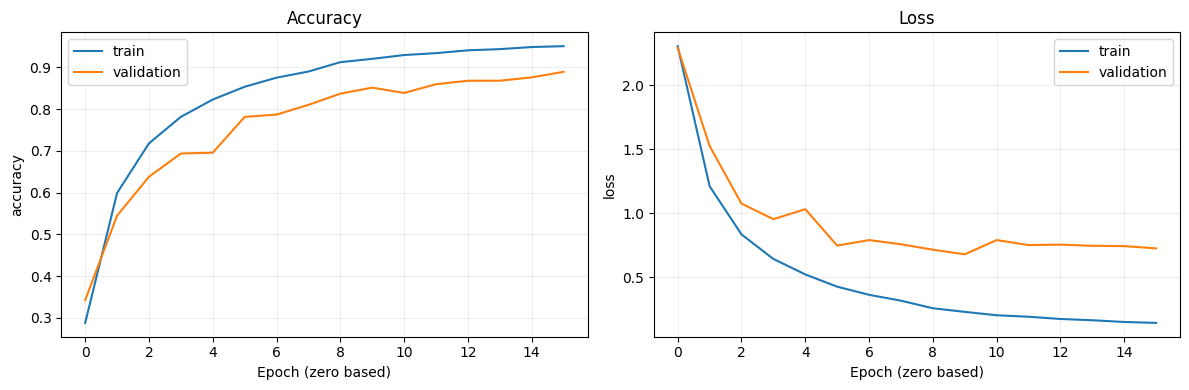

93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step
{
  "test_accuracy": 0.860515923031678,
  "test_macro_f1": 0.8594449968351744,
  "training_seconds": 168.86819780899998,
  "epochs_completed": 16,
  "parameters": 1206585,
  "test_images": 11901,
  "split_type": "exact-deduplicated filename-block split; not subject-independent"
}


,precision,recall,f1-score,support
A,0.877238,0.686000,0.769921,500.000000
B,0.796804,0.698000,0.744136,500.000000
C,0.984252,1.000000,0.992063,500.000000
D,0.855918,1.000000,0.922366,499.000000
E,0.894855,0.800000,0.844773,500.000000
F,0.836522,0.962000,0.894884,500.000000
G,0.924644,0.908000,0.916246,500.000000
H,0.928287,0.932000,0.930140,500.000000
I,0.968191,0.974000,0.971087,500.000000
K,0.964286,0.648000,0.775120,500.000000


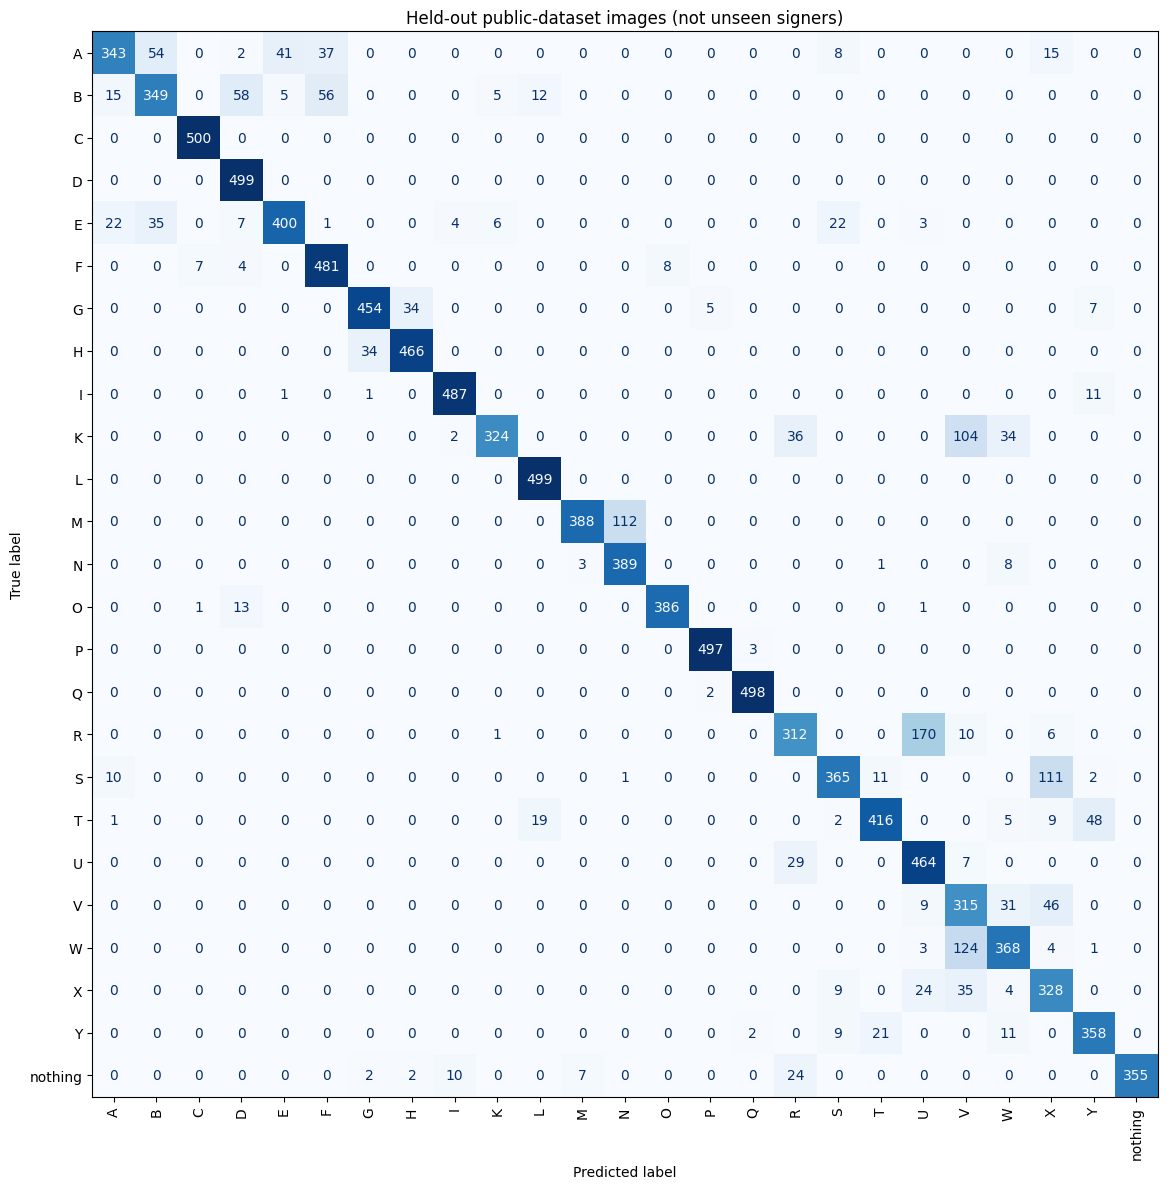

,Actual,Predicted,Count
0,R,U,170
1,W,V,124
2,M,N,112
3,S,X,111
4,K,V,104
5,B,D,58
6,B,F,56
7,A,B,54
8,T,Y,48
9,V,X,46


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key in ['accuracy', 'loss']:
    ax = axes[0 if key == 'accuracy' else 1]
    ax.plot(history_df[key], label='train')
    ax.plot(history_df['val_'+key], label='validation')
    ax.set(xlabel='Epoch (zero based)', ylabel=key, title=key.title()); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png', dpi=180); plt.show()

scores = model.predict(test_ds, verbose=1)
y_true = parts['test'].label.to_numpy()
y_pred = scores.argmax(axis=1)
metrics = dict(test_accuracy=float(accuracy_score(y_true, y_pred)),
               test_macro_f1=float(f1_score(y_true, y_pred, labels=range(len(CLASSES)), average='macro', zero_division=0)),
               training_seconds=training_seconds, epochs_completed=len(history_df),
               parameters=model.count_params(), test_images=len(y_true),
               split_type='exact-deduplicated filename-block split; not subject-independent')
report = classification_report(y_true, y_pred, labels=range(len(CLASSES)), target_names=CLASSES,
                               output_dict=True, zero_division=0)
pd.DataFrame(report).T.to_csv(OUT/'classification_report.csv')
print(json.dumps(metrics, indent=2))
display(pd.DataFrame(report).T)
predictions = parts['test'].copy()
predictions['prediction'] = [CLASSES[i] for i in y_pred]
predictions['score'] = scores.max(axis=1)
predictions.to_csv(OUT/'test_predictions.csv', index=False)
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=90, colorbar=False,
                                                      values_format='d', cmap='Blues')
ax.set_title('Held-out public-dataset images (not unseen signers)')
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png', dpi=170); plt.show()
confused = [(CLASSES[i], CLASSES[j], int(cm[i,j])) for i in range(len(CLASSES))
            for j in range(len(CLASSES)) if i != j and cm[i,j] > 0]
display(pd.DataFrame(sorted(confused, key=lambda x: -x[2])[:15],
                     columns=['Actual', 'Predicted', 'Count']))


## 8. Inspect mistakes and measure model-only speed
Visual error analysis is part of the project. The following latency uses batch size 1
on this cloud device, after warm-up. It excludes webcam capture, hand detection,
display, and temporal voting, so it must not be reported as end-to-end webcam FPS.


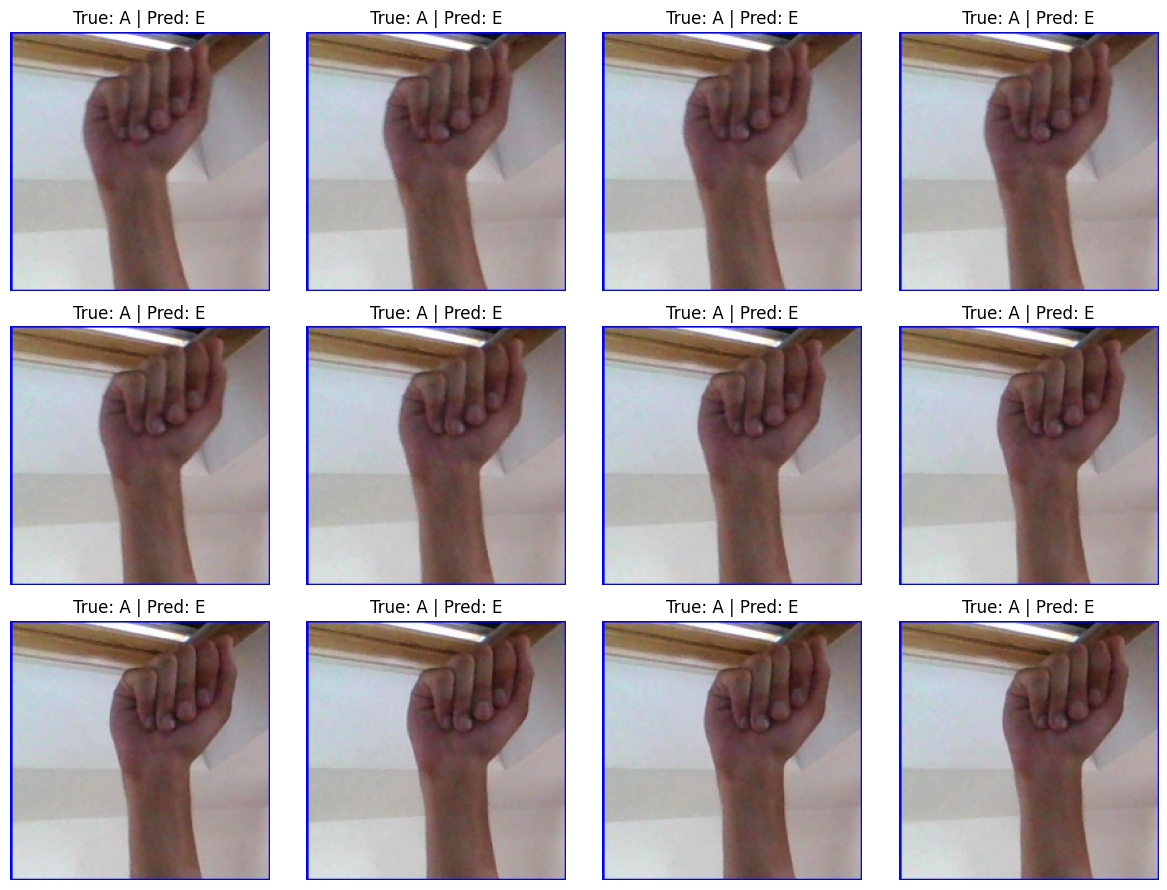

Model-only benchmark: {'cloud_model_only_latency_median_ms': 0.940919499953452, 'cloud_model_only_latency_p95_ms': 1.0371633499971722, 'cloud_model_only_fps': 1052.3866719575813}


In [11]:
wrong = np.flatnonzero(y_true != y_pred)[:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for ax in axes.flat: ax.axis('off')
    for ax, idx in zip(axes.flat, wrong):
        with Image.open(parts['test'].path.iloc[idx]) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f'True: {CLASSES[y_true[idx]]} | Pred: {CLASSES[y_pred[idx]]}')
    plt.tight_layout(); plt.savefig(OUT/'error_examples.png', dpi=160); plt.show()

sample = tf.cast(images[:1], tf.float32)
@tf.function
def predict_one(x):
    return model(x, training=False)
for _ in range(20): predict_one(sample).numpy()
latencies = []
for _ in range(100):
    t0 = time.perf_counter()
    predict_one(sample).numpy()  # synchronize GPU result
    latencies.append((time.perf_counter()-t0)*1000)
metrics['cloud_model_only_latency_median_ms'] = float(np.median(latencies))
metrics['cloud_model_only_latency_p95_ms'] = float(np.percentile(latencies, 95))
metrics['cloud_model_only_fps'] = float(1000/np.mean(latencies))
(OUT/'metrics.json').write_text(json.dumps(metrics, indent=2))
print('Model-only benchmark:', {k:v for k,v in metrics.items() if 'model_only' in k})


## 9. Optional separate volunteer evaluation
Do not use final evaluation volunteers/recording sessions for training or tuning.
Attach a separate dataset with `volunteer_test/A/*.jpg`, etc., and edit the path below.
It must use the same MediaPipe cropping/preprocessing as the webcam application.
Until such images are supplied, volunteer performance is explicitly **not measured**.


In [12]:
VOLUNTEER_ROOT = None  # e.g. Path('/kaggle/input/our-held-out-signs/volunteer_test')
if VOLUNTEER_ROOT is None:
    print('Volunteer evaluation pending. No local-user accuracy is claimed.')
else:
    vroot = Path(VOLUNTEER_ROOT)
    unknown = sorted(p.name for p in vroot.iterdir() if p.is_dir() and p.name not in CLASSES)
    if unknown: raise ValueError(f'Unknown class folders: {unknown}')
    local_rows = [dict(path=str(p), label=i) for i, name in enumerate(CLASSES)
                  for p in sorted((vroot/name).glob('*')) if p.suffix.lower() in {'.jpg','.jpeg','.png'}]
    if not local_rows: raise ValueError('No volunteer images found.')
    local_df = pd.DataFrame(local_rows)
    local_scores = model.predict(make_dataset(local_df), verbose=1)
    local_pred = local_scores.argmax(1)
    local_report = classification_report(local_df.label, local_pred, labels=range(len(CLASSES)),
                                         target_names=CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(local_report).T.to_csv(OUT/'volunteer_classification_report.csv')
    print('Volunteer accuracy:', accuracy_score(local_df.label, local_pred))
    print('Macro-F1 includes absent classes; inspect support in the report.')
    display(pd.DataFrame(local_report).T)


Volunteer evaluation pending. No local-user accuracy is claimed.


## 10. Export for the webcam application
`best_model.keras` includes augmentation (inactive during inference) and rescaling.
Feed raw RGB values 0–255. **Do not divide by 255 again.**

The accompanying `webcam.py` uses MediaPipe for a padded hand crop, then this CNN,
then majority voting. `nothing` or no hand clears the display. A high softmax score
is not calibrated confidence and is not a guarantee of rejecting unknown gestures.

Training images are the dataset's supplied hand views; webcam MediaPipe crops can
have a different distribution. Inspect live crop previews and evaluate volunteer
images before making real-world claims. No production accessibility claim is made.


In [13]:
inference_config = dict(classes=CLASSES, image_size=IMAGE_SIZE,
                        colour_order='RGB', pixel_range=[0,255],
                        resize='aspect-preserving resize_with_pad',
                        score_threshold=0.75, vote_window=7, required_votes=5,
                        hand_crop_margin=0.20, threshold_status='initial heuristic; not calibrated')
(OUT/'inference_config.json').write_text(json.dumps(inference_config, indent=2))
requirements = []
for name in ['tensorflow','keras','numpy','pandas','scikit-learn','Pillow','matplotlib']:
    try:
        from importlib.metadata import version
        requirements.append(f'{name}=={version(name)}')
    except Exception: pass
(OUT/'training_environment.txt').write_text('\n'.join(requirements)+'\n')
(OUT/'MODEL_CARD.md').write_text(
    '# Static ASL CNN\n\n'
    'Dataset: Akash Nagaraj / grassknoted/asl-alphabet. See dataset license and attribution.\n'
    '24 static ASL letters plus nothing. J/Z, sentences, and ISL are outside scope.\n'
    'Trained from scratch; selected by validation loss. See config, manifests, and metrics.\n'
    'Public test split is not subject-independent. No volunteer result unless separately provided.\n'
    'Cloud model-only FPS is not webcam end-to-end FPS. Softmax scores are uncalibrated.\n'
    'Limitations: similar signs, pose, background, lighting, hand dominance, and crop domain shift.\n'
)
archive = shutil.make_archive('/kaggle/working/asl_model_and_results', 'zip', OUT)
print('Export ready:', archive)
print('Keep this archive and the executed notebook using Save Version.')
print('Actual measured metrics:', json.dumps(metrics, indent=2))


Export ready: /kaggle/working/asl_model_and_results.zip
Keep this archive and the executed notebook using Save Version.
Actual measured metrics: {
  "test_accuracy": 0.860515923031678,
  "test_macro_f1": 0.8594449968351744,
  "training_seconds": 168.86819780899998,
  "epochs_completed": 16,
  "parameters": 1206585,
  "test_images": 11901,
  "split_type": "exact-deduplicated filename-block split; not subject-independent",
  "cloud_model_only_latency_median_ms": 0.940919499953452,
  "cloud_model_only_latency_p95_ms": 1.0371633499971722,
  "cloud_model_only_fps": 1052.3866719575813
}


## Project discussion and next checks
- Explain each convolution, pooling, dense, dropout, softmax, loss, and optimizer choice.
- Explain why augmentation is training-only and why test data cannot guide tuning.
- Explain that MediaPipe detects the hand; the CNN classifies the sign.
- Compare raw predictions with 7-frame voting on the same recorded clips. Record
  flicker/change counts and time from a held sign to a stable display; do not invent results.
- Measure webcam FPS and end-to-end latency on the laptop separately from cloud inference.
- Test different volunteers and backgrounds, including failures and no-hand frames.
- Keep this architecture within the submitted lightweight-CNN methodology; MobileNet
  is an optional later alternative only if the baseline needs a justified comparison.

### References
1. Akash Nagaraj, ASL Alphabet, Kaggle, 2018. https://www.kaggle.com/datasets/grassknoted/asl-alphabet
2. TensorFlow image classification: https://www.tensorflow.org/tutorials/images/classification
3. MediaPipe Hands: https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker
